# 🏙️ Tipologia Socioeconômica dos 5.571 Municípios Brasileiros
## Análise Multidimensional de Agrupamento: Diagnóstico de K Ideal, Simulação de 30 Rodadas e Comparação com/sem Porte Populacional

### 🎯 Objetivos Centrais desta Análise:
1. **Determinação do K Ideal:** Aplicação do **Método do Cotovelo (Inércia / WCSS)** e do **Coeficiente de Silhueta (Silhouette Score)** para $K \in [2, 10]$.
2. **Avaliação da Variável de Porte:** Comparar a estrutura dos clusters **COM o tamanho do município** (`populacao_2025` / `log_populacao`) vs. **SEM o tamanho** (apenas intensidades relativas por 100 hab e percentuais).
3. **Simulação de 30 Execuções (Estabilidade):** Rodar o K-Means 30 vezes com sementes aleatórias distintas para checar a recorrência e robustez dos padrões.
4. **Análise das Características Puras dos Grupos:** Exibir as médias das variáveis em cada cluster **sem rotular previamente**, permitindo a leitura empírica dos dados.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.spatial.distance import cdist

# Estilo editorial de visualização
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("✅ Ambiente configurado com scikit-learn, scipy, pandas e matplotlib!")


✅ Ambiente configurado com scikit-learn, scipy, pandas e matplotlib!


## 📂 1. Carregamento dos Dados e Preparação das Matrizes
Carregamos as abas auditadas do arquivo `traducao_municipios_consolidado.xlsx` e construímos dois conjuntos de variáveis:
* **Matriz A (COM Porte):** Inclui `log_populacao` junto com os indicadores per capita.
* **Matriz B (SEM Porte):** Exclui qualquer variável de população absoluta, focando na intensidade socioeconômica pura.


In [2]:
EXCEL_PATH = 'traducao_municipios_consolidado.xlsx'

print(f"⏳ Carregando bases de dados municipais de {EXCEL_PATH}...")
df_trab = pd.read_excel(EXCEL_PATH, sheet_name='Trabalho_e_Renda')
df_prev = pd.read_excel(EXCEL_PATH, sheet_name='Previdencia_Economia')
df_educ = pd.read_excel(EXCEL_PATH, sheet_name='Educacao_Escolas')
df_saude = pd.read_excel(EXCEL_PATH, sheet_name='Saude_Medicamentos')

df_mun = df_trab[['cod_ibge7', 'cod_ibge6', 'municipio', 'uf', 'populacao_2025']].copy()
pop = df_mun['populacao_2025'].replace(0, np.nan)

# Conjunto B: Indicadores de Intensidade Socioeconômica (SEM Tamanho)
features_sem_porte = {
    'taxa_clt_100_hab': (df_trab['trabalhadores_clt_ativos'] / pop) * 100,
    'taxa_mei_100_hab': (df_trab['total_mei_ativos'] / pop) * 100,
    'servidores_100_hab': (df_trab['total_servidores_publicos'] / pop) * 100,
    'aposentados_100_hab': (df_prev['aposentadorias_rgps_dezembro'] / pop) * 100,
    'peso_prev_pib_pct': df_prev['aposentadorias_sobre_pib_pct'].fillna(0),
    'familias_bf_100_hab': (df_trab['familias_bolsa_familia'] / pop) * 100,
    'bpc_100_hab': (df_trab['beneficiarios_bpc_loas'] / pop) * 100,
    'pe_de_meia_cobertura_pct': (df_educ['qtd_beneficiarios_pe_de_meia'] / df_educ['mat_em_publico'].replace(0, np.nan) * 100).fillna(0).clip(upper=100),
    'dep_fundeb_uniao_pct': (df_educ['pct_uniao_rede_municipal'] * 100).fillna(0),
    'farmacia_pop_100_hab': (df_saude['fp_total'] / pop * 100).fillna(0)
}
df_feat_sem = pd.DataFrame(features_sem_porte).fillna(0)

# Conjunto A: Inclui Porte Populacional Logarítmico (COM Tamanho)
df_feat_com = df_feat_sem.copy()
df_feat_com['log_populacao'] = np.log10(df_mun['populacao_2025'].clip(lower=100))

# Padronização Z-Score (StandardScaler)
scaler_com = StandardScaler()
X_com = scaler_com.fit_transform(df_feat_com)

scaler_sem = StandardScaler()
X_sem = scaler_sem.fit_transform(df_feat_sem)

print(f"✅ Matrizes preparadas:")
print(f" - Cenário A (COM Tamanho): {X_com.shape[1]} variáveis padronizadas para {X_com.shape[0]} cidades.")
print(f" - Cenário B (SEM Tamanho): {X_sem.shape[1]} variáveis padronizadas para {X_sem.shape[0]} cidades.")


⏳ Carregando bases de dados municipais de traducao_municipios_consolidado.xlsx...


✅ Matrizes preparadas:
 - Cenário A (COM Tamanho): 11 variáveis padronizadas para 5571 cidades.
 - Cenário B (SEM Tamanho): 10 variáveis padronizadas para 5571 cidades.


## 📐 2. Diagnóstico do K Ideal: Método do Cotovelo e Coeficiente de Silhueta
Testamos $K$ variando de **2 até 10 grupos** calculando:
1. **Inércia (WCSS - Within-Cluster Sum of Squares):** Mede a compactação dos clusters. O "cotovelo" aponta o ponto de ganho marginal decrescente.
2. **Coeficiente de Silhueta:** Varia de -1 a +1. Mede o quão bem separado cada município está dos clusters vizinhos.


⏳ Executando diagnósticos de K=2 até K=10 para ambos os cenários...


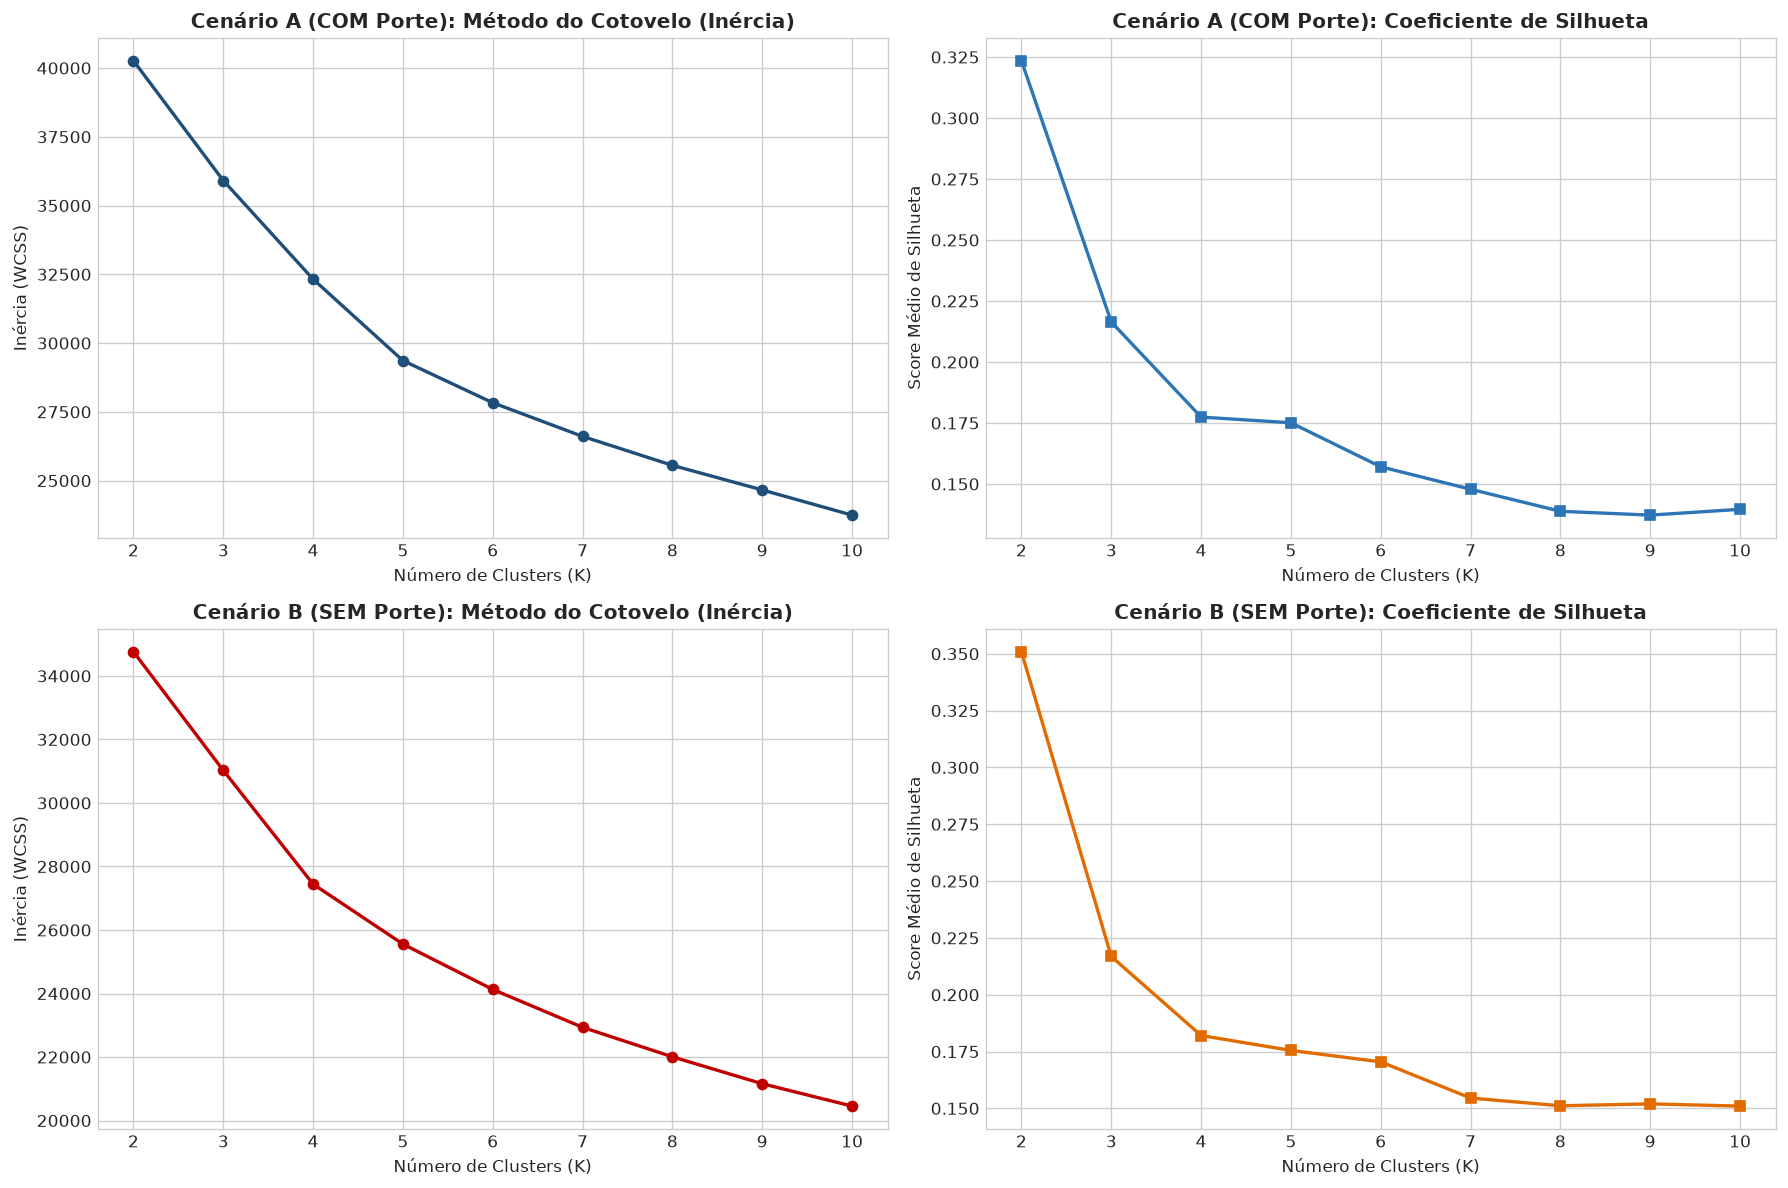

📊 Tabela Comparativa de Métricas por K:


,K,Inercia_COM,Silhueta_COM,Inercia_SEM,Silhueta_SEM
0,2,40265.4,0.323,34762.1,0.351
1,3,35909.8,0.216,31025.8,0.217
2,4,32323.3,0.177,27444.5,0.182
3,5,29363.4,0.175,25556.3,0.175
4,6,27831.7,0.157,24128.1,0.170
5,7,26607.5,0.148,22935.5,0.155
6,8,25555.7,0.139,22006.4,0.151
7,9,24661.0,0.137,21159.5,0.152
8,10,23746.4,0.140,20454.7,0.151


In [3]:
k_range = range(2, 11)
diag_com = []
diag_sem = []

print("⏳ Executando diagnósticos de K=2 até K=10 para ambos os cenários...")
for k in k_range:
    # Cenário A: Com Porte
    km_a = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab_a = km_a.fit_predict(X_com)
    sil_a = silhouette_score(X_com, lab_a)
    diag_com.append({'K': k, 'Inercia': km_a.inertia_, 'Silhueta': sil_a})
    
    # Cenário B: Sem Porte
    km_b = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab_b = km_b.fit_predict(X_sem)
    sil_b = silhouette_score(X_sem, lab_b)
    diag_sem.append({'K': k, 'Inercia': km_b.inertia_, 'Silhueta': sil_b})

df_diag_com = pd.DataFrame(diag_com)
df_diag_sem = pd.DataFrame(diag_sem)

# Gráficos Comparativos: Cotovelo e Silhueta
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Cotovelo Com Porte
axes[0, 0].plot(df_diag_com['K'], df_diag_com['Inercia'], marker='o', color='#1F4E79', lw=2)
axes[0, 0].set_title('Cenário A (COM Porte): Método do Cotovelo (Inércia)', fontweight='bold')
axes[0, 0].set_xlabel('Número de Clusters (K)')
axes[0, 0].set_ylabel('Inércia (WCSS)')

# 2. Silhueta Com Porte
axes[0, 1].plot(df_diag_com['K'], df_diag_com['Silhueta'], marker='s', color='#2E75B6', lw=2)
axes[0, 1].set_title('Cenário A (COM Porte): Coeficiente de Silhueta', fontweight='bold')
axes[0, 1].set_xlabel('Número de Clusters (K)')
axes[0, 1].set_ylabel('Score Médio de Silhueta')

# 3. Cotovelo Sem Porte
axes[1, 0].plot(df_diag_sem['K'], df_diag_sem['Inercia'], marker='o', color='#C00000', lw=2)
axes[1, 0].set_title('Cenário B (SEM Porte): Método do Cotovelo (Inércia)', fontweight='bold')
axes[1, 0].set_xlabel('Número de Clusters (K)')
axes[1, 0].set_ylabel('Inércia (WCSS)')

# 4. Silhueta Sem Porte
axes[1, 1].plot(df_diag_sem['K'], df_diag_sem['Silhueta'], marker='s', color='#E26B00', lw=2)
axes[1, 1].set_title('Cenário B (SEM Porte): Coeficiente de Silhueta', fontweight='bold')
axes[1, 1].set_xlabel('Número de Clusters (K)')
axes[1, 1].set_ylabel('Score Médio de Silhueta')

plt.tight_layout()
plt.show()

print("📊 Tabela Comparativa de Métricas por K:")
tabela_diag = df_diag_com[['K']].copy()
tabela_diag['Inercia_COM'] = df_diag_com['Inercia'].round(1)
tabela_diag['Silhueta_COM'] = df_diag_com['Silhueta'].round(3)
tabela_diag['Inercia_SEM'] = df_diag_sem['Inercia'].round(1)
tabela_diag['Silhueta_SEM'] = df_diag_sem['Silhueta'].round(3)
display(tabela_diag)


## 🔁 3. Simulação de Estabilidade: Rodando o K-Means 30 Vezes
Para verificar se os agrupamentos são robustos ou fruto de variações aleatórias da inicialização, rodamos o algoritmo **30 vezes com sementes diferentes** ($seed \in [1, 30]$) para $K=8$.
Alinhamos os centróides entre as rodadas e calculamos a média e a estabilidade de cada dimensão.


In [4]:
def executar_simulacao_30x(X_matriz, df_orig, K=6, n_runs=30):
    # Execução base (seed=42)
    km_base = KMeans(n_clusters=K, random_state=42, n_init=10)
    labels_base = km_base.fit_predict(X_matriz)
    ref_centroids = km_base.cluster_centers_
    
    lista_centroides = [ref_centroids]
    
    for s in range(1, n_runs):
        km_iter = KMeans(n_clusters=K, random_state=s, n_init=5)
        km_iter.fit(X_matriz)
        cents = km_iter.cluster_centers_
        
        # Alinhamento pelo vizinho mais próximo com os centróides de referência
        dist_matrix = cdist(cents, ref_centroids)
        alinhado = np.zeros_like(ref_centroids)
        melhores = np.argmin(dist_matrix, axis=1)
        for idx_c, idx_ref in enumerate(melhores):
            alinhado[idx_ref] = cents[idx_c]
        lista_centroides.append(alinhado)
        
    tensor_cents = np.array(lista_centroides)
    
    # Médias das 30 rodadas em escala z-score
    cents_mean_scaled = tensor_cents.mean(axis=0)
    cents_std_scaled = tensor_cents.std(axis=0)
    
    return labels_base, cents_mean_scaled, cents_std_scaled

labels_com, mean_com_sc, std_com_sc = executar_simulacao_30x(X_com, df_feat_com, K=6, n_runs=30)
labels_sem, mean_sem_sc, std_sem_sc = executar_simulacao_30x(X_sem, df_feat_sem, K=6, n_runs=30)

print("✅ Simulação de 30 execuções concluída com sucesso para ambos os cenários!")


✅ Simulação de 30 execuções concluída com sucesso para ambos os cenários!


## 🔬 4. Características Puras dos Clusters: Cenário A (COM Tamanho da Cidade)
Abaixo estão as características médias reais (desfeitas as padronizações) resultantes das 30 execuções para os **8 clusters**, sem rotulação prévia.


In [5]:
df_com_analise = df_feat_com.copy()
df_com_analise['cluster'] = labels_com
df_com_analise['populacao'] = df_mun['populacao_2025']

caract_com = df_com_analise.groupby('cluster').agg({
    'populacao': ['count', 'mean', 'median'],
    'servidores_100_hab': 'mean',
    'taxa_clt_100_hab': 'mean',
    'taxa_mei_100_hab': 'mean',
    'aposentados_100_hab': 'mean',
    'peso_prev_pib_pct': 'mean',
    'familias_bf_100_hab': 'mean',
    'pe_de_meia_cobertura_pct': 'mean',
    'dep_fundeb_uniao_pct': 'mean',
    'farmacia_pop_100_hab': 'mean'
}).round(1)

print("📋 TABELA DE CARACTERÍSTICAS PURAS (COM TAMANHO DA CIDADE) — K=8:")
display(caract_com)


📋 TABELA DE CARACTERÍSTICAS PURAS (COM TAMANHO DA CIDADE) — K=8:


populacao                    servidores_100_hab taxa_clt_100_hab  \
            count      mean   median               mean             mean   
cluster                                                                    
0            1181    6237.1   4724.0                8.5             28.0   
1             628   24154.6  18797.5                6.6             15.4   
2             985  120542.6  41256.0                4.5             27.4   
3            1183   10917.9   8129.0                6.1             28.5   
4             717    7428.5   5748.0                9.7             16.0   
5             877   61470.1  21823.0                5.9             16.0   

        taxa_mei_100_hab aposentados_100_hab peso_prev_pib_pct  \
                    mean                mean              mean   
cluster                                                          
0                    9.3                 8.1               4.2   
1                    5.8                17.3              18.9   
2                    8.9                11.9               5.3   
3                    9.5                19.7               9.7   
4                    6.2                 5.5               4.6   
5                    5.9                 8.0               6.6   

        familias_bf_100_hab pe_de_meia_cobertura_pct dep_fundeb_uniao_pct  \
                       mean                     mean                 mean   
cluster                                                                     
0                       5.6                     54.4                  3.2   
1                      13.0                     79.9                 42.7   
2                       5.7                     39.9                  2.5   
3                       5.0                     42.3                  3.3   
4                      12.5                     75.2                 25.1   
5                      12.7                     76.3                 38.4   

        farmacia_pop_100_hab  
                        mean  
cluster                       
0                        6.3  
1                        4.7  
2                        7.1  
3                       13.3  
4                        3.4  
5                        3.1

## 🔬 5. Características Puras dos Clusters: Cenário B (SEM Tamanho da Cidade / Intensidade Pura)
Neste cenário, **desprezamos a quantidade de habitantes**. Uma metrópole e uma cidade de 5 mil habitantes são agrupadas no mesmo grupo caso tenham o mesmo perfil de intensidade relativa.


In [6]:
df_sem_analise = df_feat_sem.copy()
df_sem_analise['cluster'] = labels_sem
df_sem_analise['populacao'] = df_mun['populacao_2025']

caract_sem = df_sem_analise.groupby('cluster').agg({
    'populacao': ['count', 'mean', 'median'],
    'servidores_100_hab': 'mean',
    'taxa_clt_100_hab': 'mean',
    'taxa_mei_100_hab': 'mean',
    'aposentados_100_hab': 'mean',
    'peso_prev_pib_pct': 'mean',
    'familias_bf_100_hab': 'mean',
    'pe_de_meia_cobertura_pct': 'mean',
    'dep_fundeb_uniao_pct': 'mean',
    'farmacia_pop_100_hab': 'mean'
}).round(1)

print("📋 TABELA DE CARACTERÍSTICAS PURAS (SEM TAMANHO DA CIDADE) — K=8:")
display(caract_sem)


📋 TABELA DE CARACTERÍSTICAS PURAS (SEM TAMANHO DA CIDADE) — K=8:


populacao                   servidores_100_hab taxa_clt_100_hab  \
            count     mean   median               mean             mean   
cluster                                                                   
0            1103  63468.9  15413.0                5.4             28.4   
1             581   5357.8   3518.0               10.6             26.9   
2            1417  40156.2  11093.0                7.6             16.0   
3             958  56617.6  13028.5                5.6             27.4   
4             769  26125.9  19142.0                6.4             15.4   
5             743  12207.4   7285.0                6.2             28.5   

        taxa_mei_100_hab aposentados_100_hab peso_prev_pib_pct  \
                    mean                mean              mean   
cluster                                                          
0                    9.0                12.0               5.9   
1                    9.1                 6.6               3.6   
2                    6.0                 6.3               5.2   
3                    9.3                12.0               5.6   
4                    5.7                16.4              17.6   
5                    9.5                21.8              10.7   

        familias_bf_100_hab pe_de_meia_cobertura_pct dep_fundeb_uniao_pct  \
                       mean                     mean                 mean   
cluster                                                                     
0                       6.5                     44.1                  3.0   
1                       6.1                     57.4                  2.9   
2                      12.6                     75.8                 32.4   
3                       4.2                     44.7                  3.1   
4                      13.0                     79.7                 42.1   
5                       5.1                     41.5                  2.9   

        farmacia_pop_100_hab  
                        mean  
cluster                       
0                        7.7  
1                        5.7  
2                        3.2  
3                        7.4  
4                        4.7  
5                       15.2

## 🔍 6. Comparativo dos Padrões que Mais se Repetem
Examinamos as diferenças fundamentais de estrutura entre agrupar com porte vs agrupar por intensidade socioeconômica pura.


In [7]:
# Comparação de cruzamento de matriz de contingência entre os dois cenários
tabela_contingencia = pd.crosstab(labels_com, labels_sem, rownames=['Cluster COM Porte'], colnames=['Cluster SEM Porte'])
print("📊 Matriz de Cruzamento: Onde as cidades do Cenário A vão parar no Cenário B:")
display(tabela_contingencia)

📊 Matriz de Cruzamento: Onde as cidades do Cenário A vão parar no Cenário B:


Cluster SEM Porte,0,1,2,3,4,5
Cluster COM Porte,,,,,,
0,298,539,1,340,0,3
1,1,0,0,0,627,0
2,607,4,6,348,0,20
3,194,0,0,269,0,720
4,0,38,667,1,11,0
5,3,0,743,0,131,0


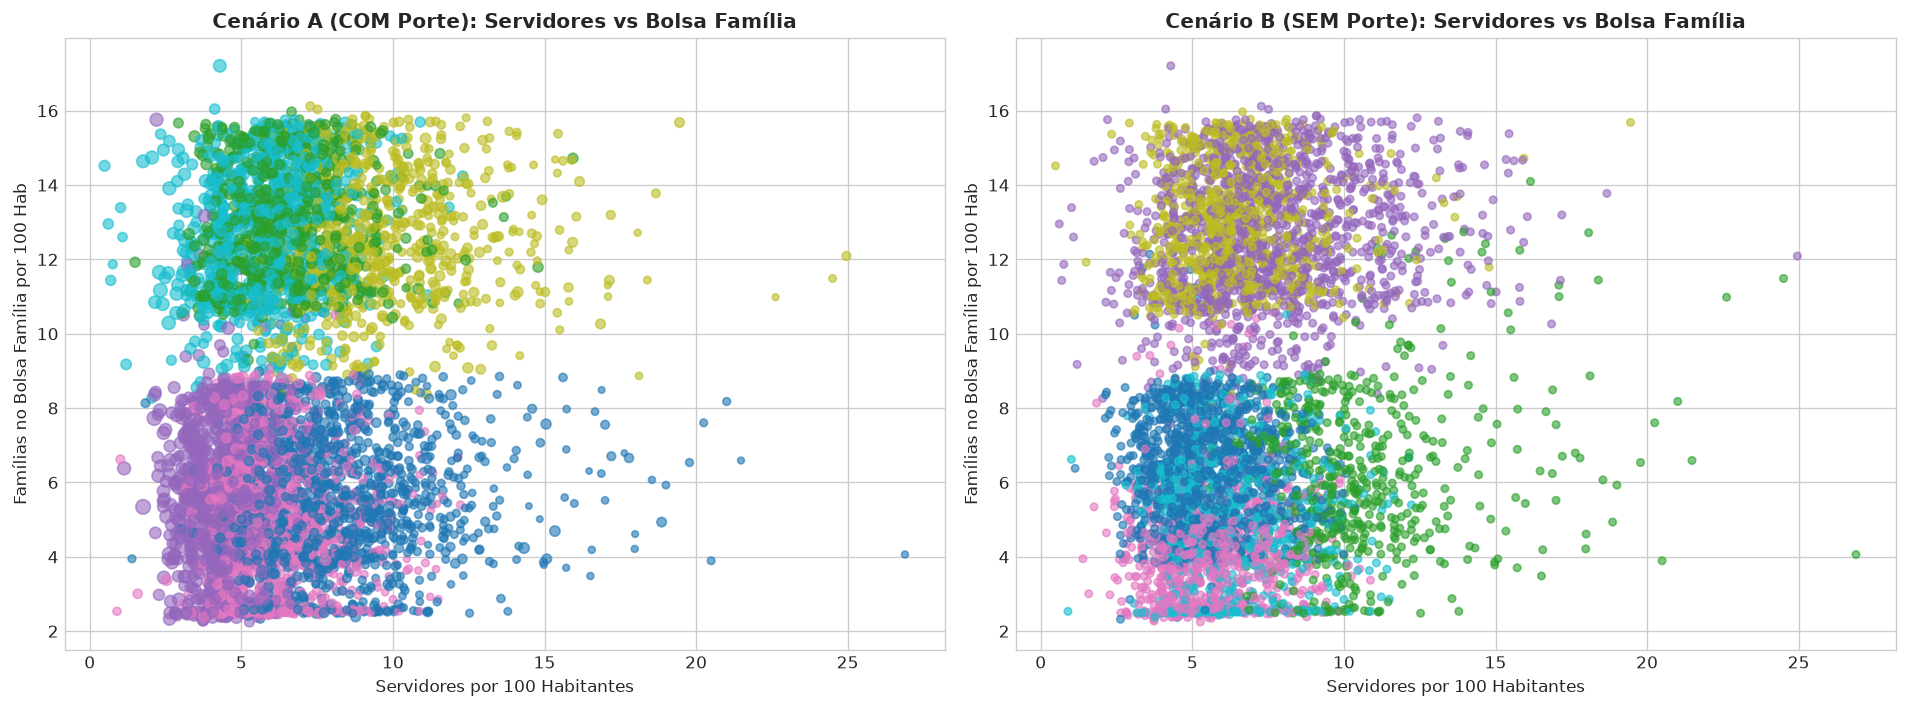

In [8]:
# Gráficos comparativos de dispersão: Força de Servidores vs Bolsa Família nos dois cenários
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Cenário A: Com Porte (tamanho do ponto proporcional ao log da população)
scatter_a = axes[0].scatter(
    df_feat_com['servidores_100_hab'],
    df_feat_com['familias_bf_100_hab'],
    c=labels_com, cmap='tab10', alpha=0.6, s=15 + (df_feat_com['log_populacao'] - 3)*15
)
axes[0].set_title('Cenário A (COM Porte): Servidores vs Bolsa Família', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Servidores por 100 Habitantes')
axes[0].set_ylabel('Famílias no Bolsa Família por 100 Hab')

# Cenário B: Sem Porte
scatter_b = axes[1].scatter(
    df_feat_sem['servidores_100_hab'],
    df_feat_sem['familias_bf_100_hab'],
    c=labels_sem, cmap='tab10', alpha=0.6, s=20
)
axes[1].set_title('Cenário B (SEM Porte): Servidores vs Bolsa Família', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Servidores por 100 Habitantes')
axes[1].set_ylabel('Famílias no Bolsa Família por 100 Hab')

plt.tight_layout()
plt.show()


## 💾 7. Exportação das Duas Classificações para a Base de Dados
Gravamos tanto `cluster_com_porte` quanto `cluster_sem_porte` em arquivo CSV estruturado para que você possa inspecionar e comparar cada cidade individualmente.


In [9]:
df_resultado = df_mun.copy()
df_resultado['cluster_k8_com_porte'] = labels_com
df_resultado['cluster_k8_sem_porte'] = labels_sem

# Juntar com as variáveis originais
df_export = pd.concat([df_resultado, df_feat_com], axis=1)

out_csv = 'dados_prioridades/clusters_com_e_sem_porte_municipios.csv'
df_export.to_csv(out_csv, sep=';', index=False)
print(f"✅ Arquivo exportado com sucesso: {out_csv}")
print("Amostra das primeiras 5 cidades:")
display(df_resultado.head(5))


✅ Arquivo exportado com sucesso: dados_prioridades/clusters_com_e_sem_porte_municipios.csv
Amostra das primeiras 5 cidades:


,cod_ibge7,cod_ibge6,municipio,uf,populacao_2025,cluster_k8_com_porte,cluster_k8_sem_porte
0,1100015,110001,Alta Floresta D'Oeste,RO,22787,2,0
1,1100023,110002,Ariquemes,RO,109170,2,3
2,1100031,110003,Cabixi,RO,5664,0,3
3,1100049,110004,Cacoal,RO,98280,2,3
4,1100056,110005,Cerejeiras,RO,16966,5,2
